# **시계열 분석**

<p align="right">15기 손영현</p>

---

## **<span style="background-color:#FCE4EC;">1. 시계열 데이터란?</span>**

### **<span style="background-color:#E3F2FD;">1.1 시계열 데이터의 정의</span>**

1) 개념
- <mark style="background-color:#CFEFFF; color:#000000">시간의 흐름에 따라 일정한 간격, 순서대로 관측·기록된 데이터</mark> (주가, 기온, 매출)
- $Y_1, Y_2, \dots, Y_t, \dots, Y_T$ ($t$: 시점, $Y_t$: t 시점의 값)
- 조건: 시간 순서가 의미를 가지고(섞으면 의미가 사라짐), 관측 간격(주기)이 일정해야 함.
- 횡단면 데이터(한 시점에 여러 대상)는 행 순서를 섞어도 되지만, 시계열(한 대상을 여러 시점)은 섞으면 안 됨.

2) 단변량 vs 다변량
- 단변량: 변수 하나만 관측하고 자기 과거로 예측 (삼성전자 일별 종가)
- 다변량: 여러 변수를 같이 보고 다른 변수 영향까지 고려 (판매량 ← 기온, 강수량, 요일)
- 다변량이 항상 좋은 건 아님. 미래 시점에도 값을 알 수 있는 변수(요일, 공휴일)인지 따져야 함.

3) 시계열 분석의 목적
- 패턴을 찾아서 <mark style="background-color:#CFEFFF; color:#000000">미래 값을 예측(Forecasting)</mark>하는 것
- 기본 가정: 과거 패턴이 미래에도 어느 정도 반복된다 → 코로나처럼 처음 있는 일은 예측 어려움, 먼 미래일수록 불확실함
- 순서: 시계열 이해 → 전처리 → 정상성 판단 → 모델링·예측
- 예측 자체보다 예측을 바탕으로 미리 결정하려고 씀 (재고, 발전량, 서버 증설 등)

### **<span style="background-color:#E3F2FD;">1.2 시계열 데이터의 특성</span>**

1) 시간 의존성
- 현재 값이 과거 값의 영향을 받음. 가까운 과거일수록 영향이 큼.
- 랜덤하게 섞어서 train/test를 나누면 미래로 과거를 맞히는 데이터 누수가 생김 → 반드시 과거로 학습, 미래로 평가

2) 계절성과 추세
- 계절성: 일정한 주기로 비슷한 패턴이 반복됨 ('언제마다 반복되나')
- 추세: 장기적으로 증가하거나 감소하는 방향성 ('어느 방향으로 가나')
- 실제로는 둘이 같이 나타나는 경우가 많음 (항공기 승객: 증가 추세 + 여름마다 최대)

3) 자기상관성
- 개념: <mark style="background-color:#CFEFFF; color:#000000">같은 변수의 현재 값과 과거 값 사이의 상관관계</mark> (오늘 더우면 내일도 더울 가능성이 높음)
- −1 ~ 1 값. 시차(lag)를 바꿔 가며 계산하면 반복 주기(계절성)를 찾을 수 있음. (월별 판매량을 12개월 전과 비교하면 높게 나옴)
- 문제점 → 일반 회귀분석을 그대로 못 씀
    - 오차항 독립성 가정 위반: $Cov(\varepsilon_t, \varepsilon_{t-1}) \neq 0$ → p-value, 신뢰구간이 왜곡됨
    - 허위 상관: 둘 다 시간에 따라 오르는 시계열이면 관계가 없어도 상관이 높게 나옴 (넷플릭스 가입자 수와 아파트 가격)
    - 예측 오차가 누적되고 패턴이 바뀔 수 있음
- → 시계열 전용 모델을 쓰거나, 차분·추세 제거 같은 전처리 후 분석해야 함.

### **<span style="background-color:#E3F2FD;">1.3 시계열 데이터의 분석요인</span>**

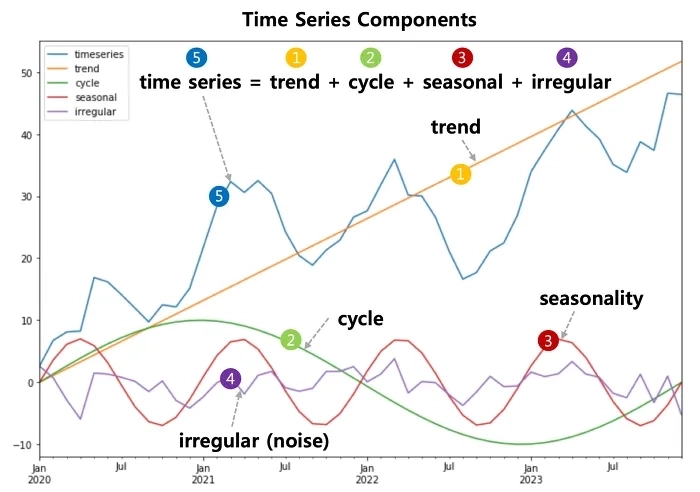

| 요인 | 의미 | 주기 | 예측 가능성 | 예시 |
|---|---|---|---|---|
| 추세 (T) | 장기적인 방향 | 없음 | 높음 | 1인 가구 수 증가 |
| 계절 (S) | 정해진 주기의 반복 | 고정 (1년 이내) | 높음 | 여름 에어컨 판매 급증 |
| 순환 (C) | 불규칙한 주기의 오르내림 | 불규칙 (수년) | 낮음 | 경기 호황·불황 |
| 불규칙 (I) | 설명되지 않는 나머지 | 없음 | 불가능 | 폭우로 매출 급감 |

- 계절은 '매년 8월'처럼 달력으로 말할 수 있고, 순환은 언제 올지 모름.
- 순환은 긴 데이터가 필요하고 추세랑 구분이 어려워서 <mark style="background-color:#CFEFFF; color:#000000">추세-순환 요인</mark>으로 묶어서 보는 경우가 많음.
- 불규칙 요인(잔차, 노이즈)은 랜덤하게 흩어져야 하고, 유독 튀는 값은 이상치일 수 있음.

---

## **<span style="background-color:#FCE4EC;">2. 시계열 데이터 전처리</span>**

[데이터 확인 → 결측치 처리 → 이상치 처리 → 평활화 → 요소분해 → 정상성 판단]

### **<span style="background-color:#E3F2FD;">2.1 결측치/이상치 처리</span>**

1) 결측치
- 행을 지우면 관측 간격이 깨지고, 전체 평균으로 채우면 시간 흐름이 무시됨 → 앞뒤 흐름을 고려해서 채워야 함.
- 방법: 삭제, 단순 대치, <mark style="background-color:#CFEFFF; color:#000000">보간</mark>(시계열에서 가장 많이 씀), 이동평균 대치, 머신러닝(KNN, 회귀)
- 보간법: 앞뒤 관측값으로 사이의 빈 값을 추정 (2일 110, 4일 130 → 직선이면 3일은 120)
    - 선형: 직선으로 연결. 빠르고 간단하지만 비선형·급변 구간에 약함
    - 다항식: 모든 점을 지나는 다항식. 비선형에 좋지만 고차는 과적합
    - 스플라인: 구간별 다항식(주로 3차)으로 부드럽게 연결
    - 조각별 상수: 앞 값(ffill), 뒤 값(bfill), 가장 가까운 값(nearest)으로 채움. 계단형 데이터에 적합
- 회귀는 오차를 허용하는 선을 긋지만, 보간은 관측값을 정답으로 보고 반드시 지나감 → 기존 값을 바꾸면 안 되니까 보간을 씀.
- 잘 모르겠으면 선형 보간부터 시작

2) 이상치
- 같은 값이라도 시점에 따라 정상/이상이 갈림 (35도: 8월이면 정상, 1월이면 이상치) → 추세·계절성을 고려해야 함.
- 탐지 방법

| 방법 | 방식 | 특징 |
|---|---|---|
| IQR | Q1 − 1.5IQR 미만, Q3 + 1.5IQR 초과 | 간단, 구간별로 적용해야 함 |
| Z-score | 평균에서 3표준편차 이상 | 정규분포 가정, Rolling으로 적용 |
| STL 분해 | 추세·계절 제거 후 잔차에 기준 적용 | 추세·계절성 반영 |
| CART, Isolation Forest | 예측 오차, 분리 횟수 기준 | 비선형 포착, 과적합 주의 |
| 클러스터링 | 군집에서 멀리 떨어진 데이터 | 비지도, 집단 이상치 탐지 |
| 오토인코더 | 정상만 학습 → 복원 오차가 크면 이상치 | 복잡한 패턴, 계산량 큼 |

- 처리: 오류인지 실제 사건인지 먼저 확인 → 보통 NaN으로 바꾼 뒤 <mark style="background-color:#CFEFFF; color:#000000">보간으로 채움</mark>

### **<span style="background-color:#E3F2FD;">2.2 평활화</span>**

- 개념: <mark style="background-color:#CFEFFF; color:#000000">자잘한 노이즈를 줄여서 큰 흐름이 보이게 만드는 것</mark>. 주로 EDA에서 씀.
- 이동평균: N개씩 묶어 평균내고 한 칸씩 옮김. $MA_t = \dfrac{Y_t + Y_{t-1} + \cdots + Y_{t-N+1}}{N}$
    - ex. 100, 130, 110, 140, 120 → N = 3이면 113, 127, 123으로 완만해짐
    - N이 작으면 변화에 빨리 반응하지만 노이즈가 남고, 크면 매끄럽지만 반응이 늦음.
    - N을 계절 주기와 같게 하면(월별 데이터에 12) 계절성이 상쇄되고 추세만 남음 → 요소분해에 쓰임
- 종류
    - SMA: 모든 값에 같은 가중치
    - WMA: 최근 값일수록 큰 가중치 (오늘 3, 어제 2, 그제 1)
    - EMA: $EMA_t = \alpha Y_t + (1-\alpha)EMA_{t-1}$, 과거로 갈수록 가중치가 지수적으로 줄어듦. α가 클수록 최근 값 중시

### **<span style="background-color:#E3F2FD;">2.3 요소분해</span>**

1) 개념
- 섞여 있는 시계열을 <mark style="background-color:#CFEFFF; color:#000000">추세(T), 계절(S), 잔차(R)로 다시 나누는 과정</mark> (순환은 추세에 포함)

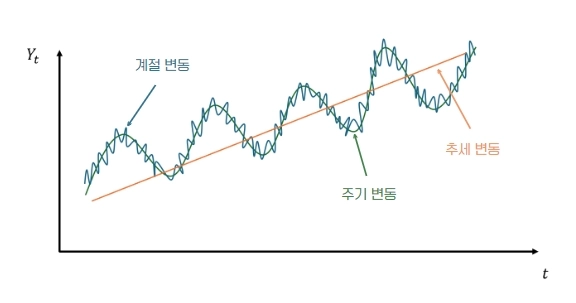

- 패턴 이해, 변동 원인 분석, 이상치 탐지, 계절조정 데이터 만들기에 씀.

2) 가법 모형 / 승법 모형
- 가법: $Y_t = T_t + S_t + R_t$ → 계절 변동 크기가 추세와 상관없이 일정 (물결 높이 일정)
- 승법: $Y_t = T_t \times S_t \times R_t$ → 추세가 커질수록 계절 변동도 비례해서 커짐 (물결 높이가 점점 커짐)
- ex. 카페 A는 여름에 항상 +50잔(가법), 카페 B는 항상 ×1.2(승법)라 규모가 커질수록 20, 40, 60잔으로 늘어남
- 매출, 주가 같은 현실 데이터는 승법에 가까운 경우가 많음. 승법에 로그를 취하면 가법처럼 다룰 수 있음.

3) seasonal_decompose / STL
- seasonal_decompose (이동평균 기반)
    1. 중심 이동평균으로 추세(T) 추출
    2. 추세 제거 (가법 Y − T, 승법 Y ÷ T)
    3. 같은 계절 위치끼리 평균내서 계절(S) 추정
    4. 남은 게 잔차(R)
- STL (LOESS 기반)
    - LOESS: 각 지점마다 주변 데이터로 작은 회귀선을 그려 이어 붙임 → 구간마다 유연하게 맞춤
    - Inner Loop: 추세 제거 → 계절 추정 → 계절 제거 → 추세 추정을 반복하며 T, S를 다듬음
    - Outer Loop: 잔차가 큰 시점에 작은 가중치를 줘서 다시 수행 → 이상치에 <mark style="background-color:#CFEFFF; color:#000000">강건(robust)</mark>
- 정리: seasonal_decompose는 단순, STL은 유연하고 강건함

---

## **<span style="background-color:#FCE4EC;">3. 정상성 판단</span>**

### **<span style="background-color:#E3F2FD;">3.1 정상성의 정의 / 강한 정상성과 약한 정상성</span>**

1) 정상성
- 개념: <mark style="background-color:#CFEFFF; color:#000000">평균, 분산, 자기상관 같은 통계적 특성이 시간에 따라 변하지 않는 성질</mark>
- 정상 시계열은 일정한 평균 주위를 오르내리고 벗어나도 돌아옴 (주가 등락률). 비정상은 추세, 계절성, 분산 변화가 있음 (주가 자체, GDP)
- '과거 패턴이 미래에도 반복된다'는 가정이 성립해야 예측이 가능해서 중요함. 매년 범위가 바뀌는 시험은 기출이 소용없는 것과 같음.

2) 강한 정상성
- 확률분포 자체가 시간에 따라 전혀 안 변함. 어떤 시점들을 h만큼 옮겨도 결합분포가 같아야 함.
- 평균, 분산뿐 아니라 왜도, 첨도까지 일정 → 현실에선 거의 없음

3) 약한 정상성
- 평균 일정, 분산 일정, <mark style="background-color:#CFEFFF; color:#000000">자기공분산이 시점이 아니라 시차(h)에만 의존</mark> (1월 1일↔2일 관계 = 7월 1일↔2일 관계)
- AR, MA, ARIMA 등 대부분 모델이 가정하는 게 약한 정상성

### **<span style="background-color:#E3F2FD;">3.2 정상성의 판단: 시각 / 통계</span>**

1) 시각적 판단
- 정상: 수평선 중심으로 비슷한 폭으로 오르내리고 평균으로 돌아옴
- 비정상: 계속 오르거나 내림(추세), 주기적 반복(계절성), 폭이 점점 커짐(분산 변화, 나팔 모양)

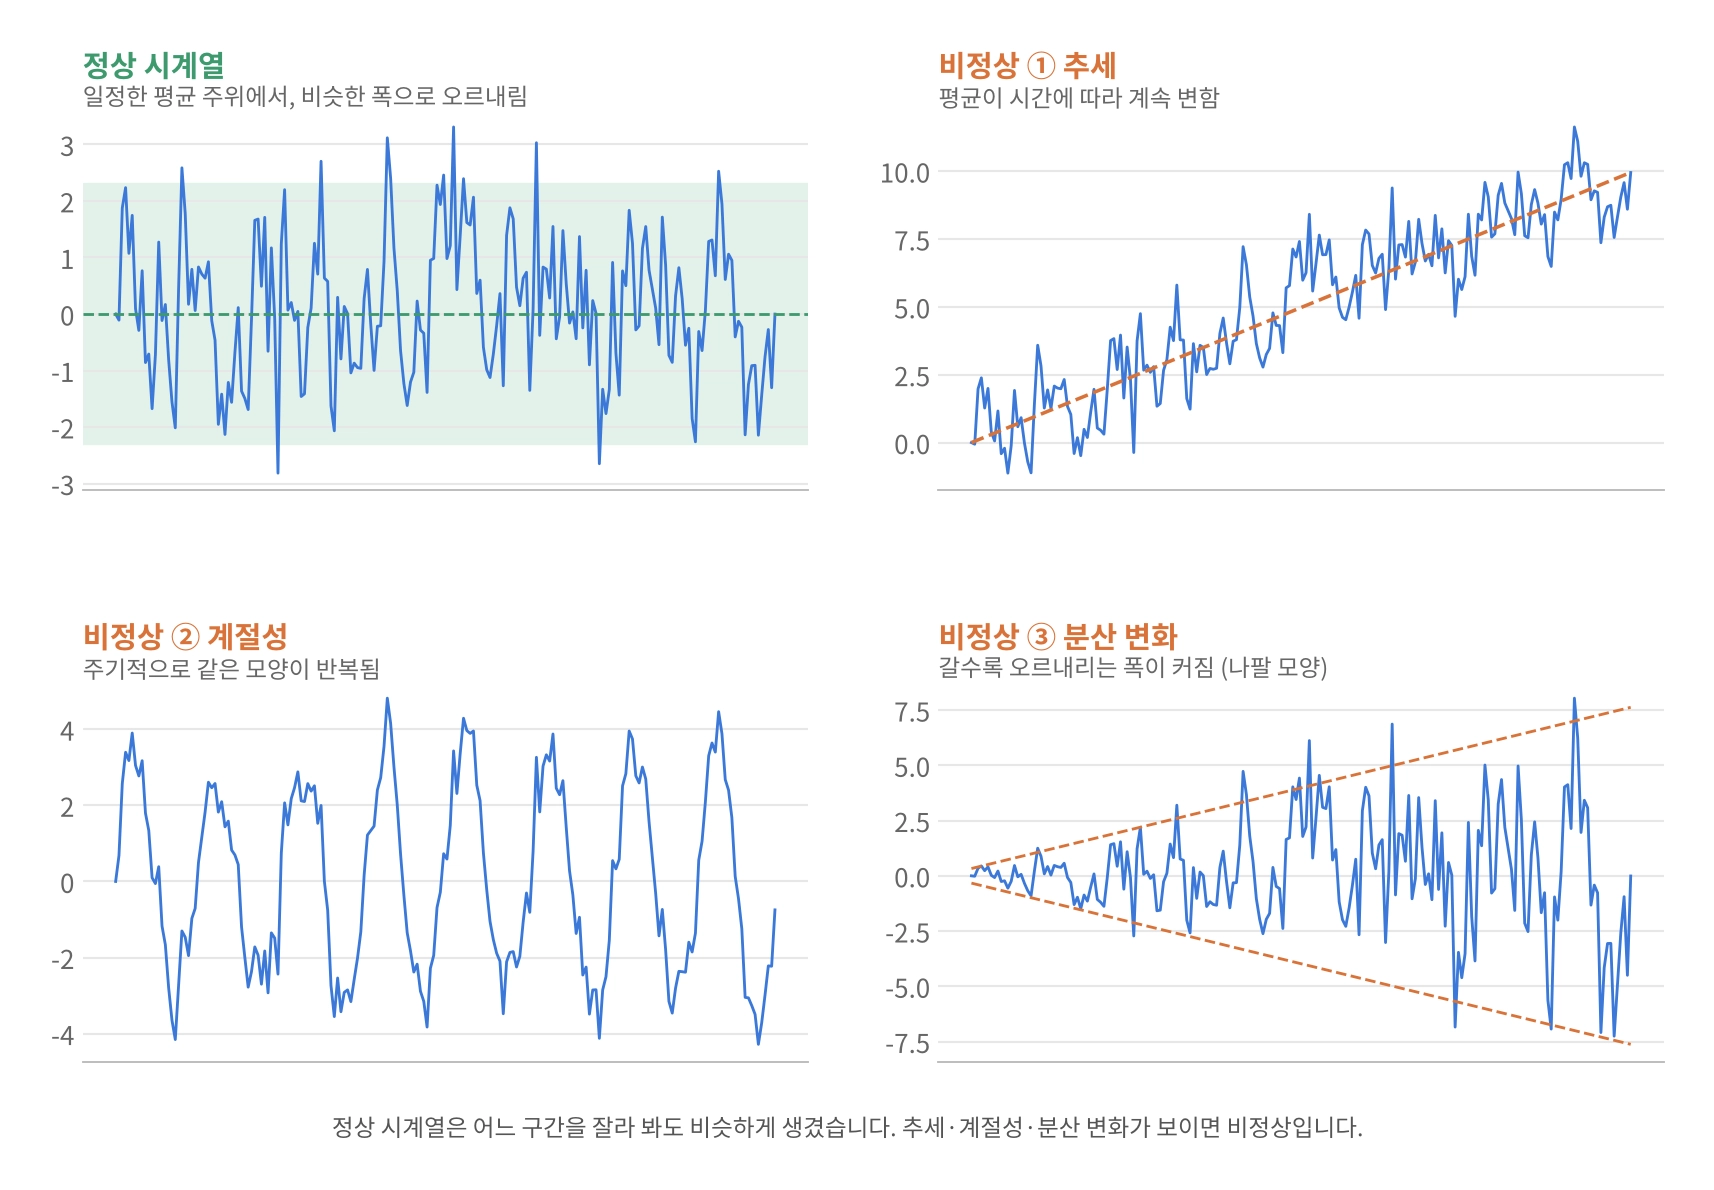

- ACF로도 확인 가능. 정상이면 막대가 빠르게 0으로 떨어지고, 비정상이면 아주 천천히 줄어듦.

2) 통계적 검정
- 단위근: 과거 충격이 사라지지 않고 계속 쌓이는 성질 → <mark style="background-color:#CFEFFF; color:#000000">단위근이 있으면 비정상</mark>
    - $Y_t = \phi Y_{t-1} + \varepsilon_t$에서 φ = 0.5면 충격이 점점 사라지고(정상), φ = 1이면 그대로 쌓임(단위근)
    - 충격이 쌓이면 평균으로 안 돌아오고 분산도 계속 커짐 → 약한 정상성이 깨짐.
- ADF와 KPSS는 귀무가설이 반대임.

| 검정 | 귀무가설 (H₀) | p-value < 0.05면 |
|---|---|---|
| ADF | 단위근 있음 (비정상) | 정상 |
| KPSS | 정상 | 비정상 |

- 두 결과 조합

| ADF | KPSS | 진단 | 다음 |
|---|---|---|---|
| 정상 | 정상 | 정상 | 바로 모델링 |
| 비정상 | 비정상 | 비정상 | 차분 후 재검정 |
| 비정상 | 정상 | 추세 정상 | 추세 제거 |
| 정상 | 비정상 | 차분 정상 | 차분 |

- 출발점이 반대라서 서로 보완해 줌 → 실무에선 둘 다 씀.

### **<span style="background-color:#E3F2FD;">3.3 정상성 확보 방법</span>**

1) 추세 제거 → 차분
- $\Delta Y_t = Y_t - Y_{t-1}$: 값 대신 '얼마나 변했나'를 봄 (100, 112, 119, 133 → +12, +7, +14)
- 추세가 사라지고, 단위근 시계열도 '오늘 새로 생긴 충격'만 남아서 정상이 됨.
- 1차 차분으로 안 되면 2차 차분. 많이 하면 오히려 없던 패턴이 생겨서 보통 2차까지만, 검정하면서 최소 횟수만 함.
- 차분한 데이터로 예측하면 결과가 변화량이라 <mark style="background-color:#CFEFFF; color:#000000">역차분</mark>으로 되돌려야 함.

2) 계절성 제거 → 계절 차분
- $\Delta_m Y_t = Y_t - Y_{t-m}$: 한 주기 전과 비교 (올해 8월 vs 작년 8월)

3) 분산 안정화 → 로그 변환
- 큰 값은 많이, 작은 값은 조금 줄여서 변동 폭을 맞춤 (10, 100, 1000 → 1, 2, 3)
- 0이나 음수엔 못 씀(1을 더하고 취하기도 함), 값에 비례해서 폭이 커지는 경우에만 효과적

---

## **<span style="background-color:#FCE4EC;">4. 단변량 시계열 분석</span>**

[변수 하나의 기록만 가지고 자기 과거로 분석·예측]

### **<span style="background-color:#E3F2FD;">4.1 안정적 시계열 분석</span>**

- 안정적 시계열 = 정상 시계열 = 돌아갈 '평소'가 있는 시계열 (판매량이 일정 수준 주변을 오르내리는 동네 가게)
- 값(y): 그날 관측된 결과 / 충격(ε): 그날 새로 생긴 예측할 수 없는 변동 (미리 아는 주말 효과, 할인 행사는 충격이 아님)

1) AR (자기회귀)
- <mark style="background-color:#CFEFFF; color:#000000">오늘 값을 자기 자신의 과거 값으로 설명</mark> → 자기상관성 활용
- $AR(p): y_t = c + \phi_1 y_{t-1} + \cdots + \phi_p y_{t-p} + \varepsilon_t$
- 손님이 어제 손님 수를 보고 오는 가게. 방송 충격 100, 계수 0.8 → 100, 80, 64, 51… 끝없이 이어지며 옅어짐 (어제 값 안에 그저께 값이 들어 있어서)

2) MA (이동평균)
- <mark style="background-color:#CFEFFF; color:#000000">오늘 값을 과거의 충격으로 설명</mark>
- $MA(q): y_t = \mu + \varepsilon_t + \theta_1 \varepsilon_{t-1} + \cdots + \theta_q \varepsilon_{t-q}$
- 손님이 지난 방송을 보고 오는 가게. 충격 100, 계수 0.8 → 100, 80, 0, 0… q일 뒤에 딱 끊김

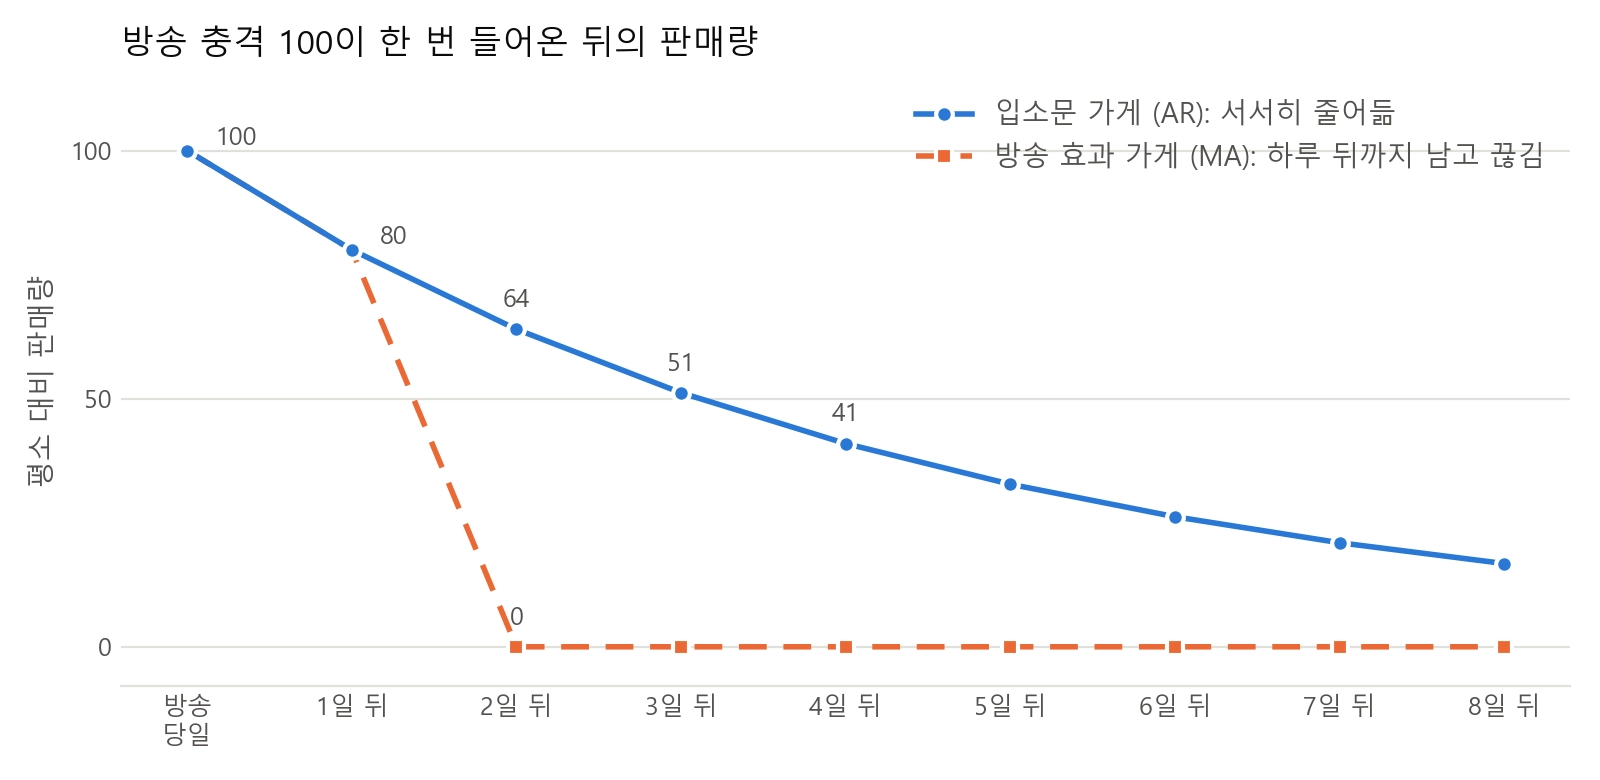

- 예측할 때 오늘 충격은 아직 모르니까 0으로 둠.

3) AR, MA의 전제조건

| | 정상성 (충격 후 평소로 돌아옴) | 가역성 (기록으로 지난 충격을 계산 가능) |
|---|---|---|
| AR | 계수 조건 필요 | 항상 만족 |
| MA | 항상 만족 | 계수 조건 필요 |

- AR(1)은 계수 절댓값이 1보다 작아야 정상 (0.8이면 줄고, 1이면 그대로, 1.1이면 불어남). AR(p)는 특성방정식의 모든 근의 절댓값이 1보다 커야 함.
- MA(1)은 계수 절댓값이 1보다 작아야 가역. 첫날 충격을 0으로 어림한 오차가 날마다 계수만큼 곱해지기 때문 (0.5면 줄고 2면 불어남)
- ADF, KPSS는 '데이터'의 정상성을 보는 거고, '모델'의 정상성은 추정한 계수로 특성방정식을 확인함.

4) ARMA
- AR + MA: 오늘 값이 과거 값과 과거 충격 양쪽의 영향을 받음.
- $y_t = c + \phi_1 y_{t-1} + \cdots + \varepsilon_t + \theta_1 \varepsilon_{t-1} + \cdots$
- ex. AR 0.5, MA 0.4에 충격 100 → 100, 90(50 + 40), 45, 22.5
- AR만 쓸 때보다 적은 계수로 설명 가능. AR 부분은 정상성, MA 부분은 가역성을 만족해야 함.

5) 차수 결정: ACF, PACF
- ACF: 오늘과 k시점 전의 상관. 중간 시점을 거친 영향까지 포함 → <mark style="background-color:#CFEFFF; color:#000000">MA 차수 q</mark> 결정
- PACF: 중간 시점의 영향을 빼고 직접 상관만 잼 → <mark style="background-color:#CFEFFF; color:#000000">AR 차수 p</mark> 결정
- 점선(보통 ±1.96/√n) 안이면 0으로 봄.

| ACF | PACF | 모델 |
|---|---|---|
| 천천히 감소 | p+1부터 0 근처 | AR(p) |
| q+1부터 0 근처 | 천천히 감소 | MA(q) |
| q+1부터 0 근처 | p+1부터 0 근처 | ARMA(p, q) |

- 막대가 급격히 줄어들기 직전의 시차를 고르면 됨.

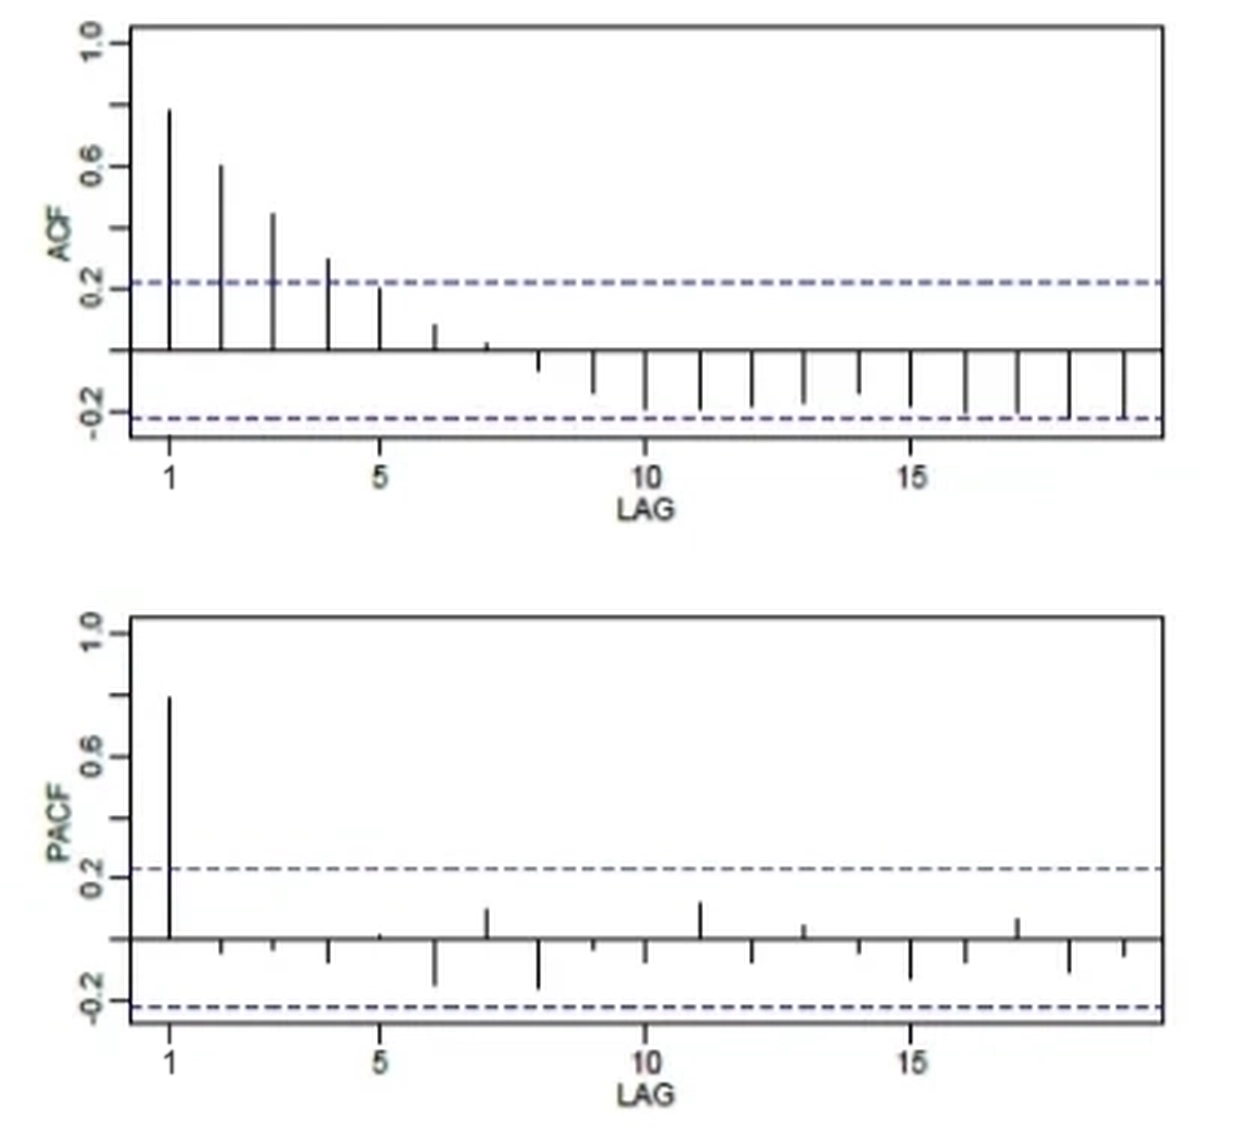

### **<span style="background-color:#E3F2FD;">4.2 불안정 시계열 분석</span>**

- 돌아갈 평소가 없는 비정상 시계열. 추세면 차분(d), 계절성이면 계절 차분(D)
- 키는 평소가 없지만 '1년간 자란 길이'는 평소가 있음 → <mark style="background-color:#CFEFFF; color:#000000">모형을 고치는 게 아니라 데이터를 모형이 다룰 수 있게 바꿔 주는 것</mark>
- 비정상 → 차분으로 정상성 확보 → ARMA

1) ARIMA(p, d, q)
- ARMA에 차분을 더한 모형 (d: 차분 횟수)
- 흐름: ① 차분해서 증감 $w_t = y_t - y_{t-1}$을 만들고 ② 증감을 ARMA로 예측하고 ③ 마지막 값에 더해서 되돌림
- ex. 판매량 100, 103, 104, 108, 110 → 증감 +3, +1, +4, +2 → 증감 +2.5 예측 → 6일 예측 112.5
- 특수한 경우: ARIMA(0,0,0) 백색잡음, (p,0,0) = AR(p), (0,0,q) = MA(q)
- 랜덤워크(상수 없는 ARIMA(0,1,0)): $Y_t = Y_{t-1} + \varepsilon_t$ → 내일 최선의 예측은 오늘 값 (주가, 환율)
- 표류를 포함하는 랜덤워크(상수 있는 ARIMA(0,1,0)): $Y_t = Y_{t-1} + c + \varepsilon_t$ → 떠돌면서도 한 방향으로 흘러감 (110 → 112.5 → 115)

2) SARIMA(p, d, q)(P, D, Q)ₘ
- ARIMA에 <mark style="background-color:#CFEFFF; color:#000000">계절 차분과 계절 AR, 계절 MA</mark>를 더한 모형
- 지난달 대비 증감은 추세를, 작년 같은 달 대비 증감은 계절마다 다른 수준을 없앰.
- ex. 붕어빵 가게: 10월, 11월이 작년보다 +50 → 12월도 작년 900 + 50 = 950으로 예측
- P, D, Q는 p, d, q를 한 주기 전 기준으로 한 번 더 하는 것, m은 한 주기가 몇 시점인지 (월별 12, 분기별 4, 요일 7)
- 계절성이 있으면 ACF가 시차 12, 24, 36에서 다시 솟음 → 계절 차분을 먼저 해야 p, q를 읽을 수 있음.

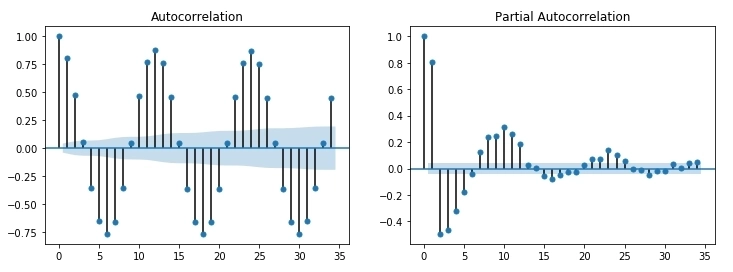

3) 하이퍼파라미터 결정
- d, D: ADF로 정상성 확인 → 정상이 나올 때까지 차분, 그 횟수가 d, D (대부분 0 또는 1)
- p, q: ACF, PACF로 범위를 잡고 → <mark style="background-color:#CFEFFF; color:#000000">AIC, BIC가 가장 낮은 조합</mark>을 그리드 서치로 고름 (보통 0~3 범위, 그래프로 잡은 값 ±1)

---

## **<span style="background-color:#FCE4EC;">5. 다변량 시계열 분석</span>**

### **<span style="background-color:#E3F2FD;">5.1 VAR</span>**

1) 개념
- <mark style="background-color:#CFEFFF; color:#000000">AR을 변수 여러 개로 넓힌 것</mark>. 각 변수를 자기 과거와 다른 변수의 과거로 같이 예측함.
- VAR(1) (X: 판매량, Y: 광고비)
    - $X_t = a_{11} X_{t-1} + a_{12} Y_{t-1} + \varepsilon_{x,t}$
    - $Y_t = a_{21} X_{t-1} + a_{22} Y_{t-1} + \varepsilon_{y,t}$
    - $a_{11}, a_{22}$는 자기 영향(AR 계수), $a_{12}, a_{21}$이 서로 주는 영향으로 새로 생긴 부분
- ex. 오늘 판매량 = 어제 판매량 × 0.6 + 어제 광고비 × 0.3 / 오늘 광고비 = 어제 광고비 × 0.5 − 어제 판매량 × 0.2 → 광고가 판매를 올리고, 잘 팔리면 광고를 줄임

2) 적합한 경우 / 부적합한 경우
- 적합: 변수끼리 양방향으로 영향을 주고받음, 변수가 적고 데이터가 충분함, 모든 변수가 정상(또는 차분하면 정상)
- 부적합: 영향이 한 방향뿐 (기온 → 판매량은 단변량에 설명변수로), 변수는 많은데 데이터가 적음 (변수 3개면 계수 9개)
- 변수 선택: Granger 인과관계 검정 → 'X의 과거가 Y 예측에 도움이 되나'를 검정해서 p < 0.05면 포함. 진짜 인과가 아니라 예측 도움만 의미함 (닭 울음 → 해 뜸)

3) 분석 방법
- 충격 반응 함수(IRF): 한 변수에 충격을 줬을 때 다른 변수가 시간에 따라 어떻게 반응하는지 → 광고 충격 100이면 판매량이 0, 30, 33, 25.5… 로 이틀 뒤에 가장 큼
- 예측오차 분산 분해: 예측이 빗나간 정도를 어느 쪽 충격 탓인지 비율로 나눔 → 판매량 1일 뒤는 100% 판매 쪽, 5일 뒤는 광고 쪽이 17%
- IRF는 '어떻게 반응하나', 분산 분해는 '누구 영향이 얼마나 큰가'

---

## **<span style="background-color:#FCE4EC;">6. 딥러닝을 활용한 시계열 분석</span>**

- 통계 모델은 데이터가 많으면 느리고, 비선형 패턴을 잡기 어려워서 딥러닝을 씀.
- RNN 계열: RNN(간단, 장기 의존성 약함), LSTM(게이트로 장기 기억), GRU(LSTM보다 빠름)
- Transformer 계열: Informer(긴 시계열, 연산 줄임), Autoformer(요소분해를 구조에 결합, 주기성에 강함), TFT(외부 변수 결합 + 어텐션으로 해석 가능, 실무 활용도 높음)
- Foundation Model: 대규모로 사전학습한 범용 모델 (TimeGPT, TimesFM, Chronos 등)
- 데이터가 적으면 오히려 ARIMA 같은 <mark style="background-color:#CFEFFF; color:#000000">통계 모델이 더 나을 수 있음</mark>

---

## **<span style="background-color:#FCE4EC;">7. 정리</span>**

- 시계열: 순서가 의미 있는 데이터. 시간 의존성, 추세·계절성, 자기상관 때문에 일반 회귀를 그대로 못 씀
- 전처리: 결측치·이상치는 보간으로, 평활화로 큰 흐름 확인, 요소분해로 T·S·R 분리 (가법/승법, seasonal_decompose/STL)
- 정상성: 평균·분산·자기공분산이 일정해야 함 → ADF·KPSS로 판단, 차분·계절 차분·로그 변환으로 확보
- 단변량: AR(과거 값), MA(과거 충격), ARMA, 차수는 ACF·PACF와 AIC·BIC로 / 비정상이면 ARIMA, 계절성까지 있으면 SARIMA
- 다변량: VAR로 변수끼리 주고받는 영향까지 예측, IRF와 분산 분해로 해석